<a href="https://colab.research.google.com/github/doomchitdoomchit/OD_DAY_SIDO_SEOULGU/blob/master/notebook/%EC%A7%80%EC%97%AD%EB%B3%84_%EC%83%81%ED%92%88_%EB%AC%BC%EB%8F%99%EB%9F%89_%ED%86%B5%EA%B3%84_%EB%8D%B0%EC%9D%B4%ED%84%B0_ADDtargetweek.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import os
import holidays

import polars as pl
import pandas as pd
import numpy as np
import lightgbm as lgb

from datetime import timedelta
from sklearn.metrics import mean_squared_error, mean_absolute_error

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
drive_path = '/content/drive/My Drive/Colab Notebooks/지역별 상품 물동량 통계 데이터'
data_name = 'seoulgu.parquet'

In [23]:
# data load
lazy_df = pl.scan_parquet(os.path.join(drive_path, data_name))

In [24]:
all_cols = lazy_df.columns
cat_cols = [c for c in all_cols if c.startswith('CAT_VOL_')]

/tmp/ipykernel_937/2883817882.py:1: PerformanceWarning: Determining the column names of a LazyFrame requires resolving its schema, which is a potentially expensive operation. Use `LazyFrame.collect_schema().names()` to get the column names without this warning.
  all_cols = lazy_df.columns


In [ ]:
# 날짜 타입 변환 및 11개 카테고리 수평 합산 (total_vol)
lazy_processed = lazy_df.with_columns([
    pl.col('DELIVERY_YMD').cast(pl.Date).alias('DELIVERY_YMD'),
    pl.sum_horizontal(cat_cols).alias('total_vol') ])


In [ ]:
# (2) 자치구 및 일자별 집계 및 정렬
lazy_daily = (
    lazy_processed.group_by(['DELIVERY_YMD', 'RECEIVER_SIGUNGU_NM']).agg(
        pl.col('total_vol').sum()
        ).sort(['RECEIVER_SIGUNGU_NM', 'DELIVERY_YMD'])
    )


In [ ]:
# (3) 시계열 피처 생성 (캘린더 + 시차 Lag + 이동 통계량 Rolling)
lags = [7, 14, 21, 28]
windows = [7, 14, 28]

# Lag 피처 표현식
lag_exprs = [
    pl.col('total_vol').shift(lag).over('RECEIVER_SIGUNGU_NM').alias(f'vol_lag_{lag}')
    for lag in lags
]

# Rolling 피처 표현식 (Data Leakage 방지를 위해 Shift 7 적용)
rolling_exprs = []
for w in windows:
    rolling_exprs.append(
        pl.col('total_vol').shift(7).rolling_mean(window_size=w)
        .over('RECEIVER_SIGUNGU_NM').alias(f'rolling_mean_{w}'))
    rolling_exprs.append(
        pl.col('total_vol').shift(7).rolling_std(window_size=w)
        .over('RECEIVER_SIGUNGU_NM').alias(f'rolling_std_{w}'))


In [54]:
# 1. 자치구별 정적 프로파일 & 학습 가중치 생성 모듈
def compute_dynamic_district_profiles(lazy_df: pl.LazyFrame) -> pl.LazyFrame:
    all_cols = lazy_df.collect_schema().names()
    cat_cols = [c for c in all_cols if c.startswith('CAT_VOL_')]

    lazy_daily = (
        lazy_df
        .with_columns([
            pl.col('DELIVERY_YMD').cast(pl.Date).alias('DELIVERY_YMD'),
            pl.sum_horizontal(cat_cols).alias('total_vol')
        ])
        .group_by(['DELIVERY_YMD', 'RECEIVER_SIGUNGU_NM'])
        .agg([
            pl.col('total_vol').sum(),
            pl.col('CAT_VOL_FOOD').sum().alias('vol_food'), # 변수 중요도 0
            pl.col('CAT_VOL_FASHION_CLOTHING').sum().alias('vol_fashion'),
            pl.col('CAT_VOL_BOOKS_MUSIC').sum().alias('vol_bookmusic'),
            pl.col('CAT_VOL_DIGITAL_APPLIANCES').sum().alias('vol_digital'),
        ])
        .sort(['RECEIVER_SIGUNGU_NM', 'DELIVERY_YMD'])
    )

    # 최근 7일 동적 카테고리 비중 (shift 1 적용으로 Data Leakage 방지)
    df_dynamic = lazy_daily.with_columns([
        (pl.col('vol_food').shift(1).rolling_sum(7).over('RECEIVER_SIGUNGU_NM') /
         (pl.col('total_vol').shift(1).rolling_sum(7).over('RECEIVER_SIGUNGU_NM') + 1e-5)
        ).alias('rolling_food_ratio_7'),

        (pl.col('vol_fashion').shift(1).rolling_sum(7).over('RECEIVER_SIGUNGU_NM') /
         (pl.col('total_vol').shift(1).rolling_sum(7).over('RECEIVER_SIGUNGU_NM') + 1e-5)
        ).alias('rolling_fashion_ratio_7'),

        (pl.col('vol_bookmusic').shift(1).rolling_sum(7).over('RECEIVER_SIGUNGU_NM') /
         (pl.col('total_vol').shift(1).rolling_sum(7).over('RECEIVER_SIGUNGU_NM') + 1e-5)
        ).alias('rolling_bookmusic_ratio_7'),

        (pl.col('vol_digital').shift(1).rolling_sum(7).over('RECEIVER_SIGUNGU_NM') /
         (pl.col('total_vol').shift(1).rolling_sum(7).over('RECEIVER_SIGUNGU_NM') + 1e-5)
        ).alias('rolling_digital_ratio_7')
    ])

    # 자치구별 스케일 가중치 (Sample Weight)
    dist_weights = lazy_daily.group_by('RECEIVER_SIGUNGU_NM').agg(
        pl.col('total_vol').mean().alias('district_avg_vol')
    ).with_columns(
        (pl.col('district_avg_vol') / pl.col('district_avg_vol').mean()).alias('sample_weight')
    )

    return df_dynamic.join(dist_weights.select(['RECEIVER_SIGUNGU_NM', 'sample_weight']), on='RECEIVER_SIGUNGU_NM', how='left')

# 2. 공휴일 전후 이월/쏠림 피처 생성
def create_holiday_features(lazy_df: pl.LazyFrame, start_year: int = 2019, end_year: int = 2023) -> pl.LazyFrame:
    """
    대한민국 공휴일 및 연휴 직전(D-1, D-2), 직후(D+1, D+2) 이월/쏠림 피처를 생성합니다.
    """
    kr_holidays = list(holidays.KR(years=range(start_year, end_year + 1)).keys())

    # (1) 휴무일 판별 (일요일 또는 법정 공휴일)
    df_feat = lazy_df.with_columns([
        (
            (pl.col('DELIVERY_YMD').dt.weekday() == 7) |
            (pl.col('DELIVERY_YMD').is_in(kr_holidays))
        ).cast(pl.Int64).alias('is_off_day')
    ])

    # (2) 연속 휴무 구간 ID 식별
    df_feat = df_feat.with_columns([
        (pl.col('is_off_day') != pl.col('is_off_day').shift(1)).fill_null(True).cum_sum().alias('off_block_id')
    ])

    # (3) 연속 휴무 일수 산출
    off_stats = (
        df_feat.filter(pl.col('is_off_day') == 1)
        .group_by('off_block_id')
        .agg(pl.col('is_off_day').sum().alias('consecutive_off_days'))
    )

    # (4) 전후 연휴 일수 및 피처 6종 생성
    df_final = (
        df_feat.join(off_stats, on='off_block_id', how='left')
        .with_columns(pl.col('consecutive_off_days').fill_null(0))
        .with_columns([
            pl.col('consecutive_off_days').shift(1).over('RECEIVER_SIGUNGU_NM').fill_null(0).alias('prev_off_days'),
            pl.col('consecutive_off_days').shift(-1).over('RECEIVER_SIGUNGU_NM').fill_null(0).alias('next_off_days')
        ])
        .with_columns([
            # Post-Holiday (연휴 직후 이월)
            ((pl.col('is_off_day') == 0) & (pl.col('prev_off_days') > 0)).cast(pl.Int64).alias('is_post_holiday_d1'),
            ((pl.col('is_off_day') == 0) & (pl.col('prev_off_days').shift(1).over('RECEIVER_SIGUNGU_NM') > 0)).cast(pl.Int64).alias('is_post_holiday_d2'),
            pl.when((pl.col('is_off_day') == 0) & (pl.col('prev_off_days') > 0)).then(pl.col('prev_off_days')).otherwise(0).alias('backlog_impact_score'),

            # Pre-Holiday (연휴 직전 쏠림)
            ((pl.col('is_off_day') == 0) & (pl.col('next_off_days') > 0)).cast(pl.Int64).alias('is_pre_holiday_d1'),
            ((pl.col('is_off_day') == 0) & (pl.col('next_off_days').shift(-1).over('RECEIVER_SIGUNGU_NM') > 0)).cast(pl.Int64).alias('is_pre_holiday_d2'),
            pl.when((pl.col('is_off_day') == 0) & (pl.col('next_off_days') > 0)).then(pl.col('next_off_days')).otherwise(0).alias('pre_holiday_impact_score')
        ])
    )
    return df_final


# 3. 캘린더 & 교차 변수 생성 모듈
def create_calendar_and_interaction_features(lazy_df: pl.LazyFrame) -> pl.LazyFrame:
    """
    [전략 3] 캘린더 변수 및 공휴일 x 요일 교차(Interaction) 피처를 생성합니다.
    """
    return lazy_df.with_columns([
        pl.col('DELIVERY_YMD').dt.year().alias('year'),
        pl.col('DELIVERY_YMD').dt.month().alias('month'),
        pl.col('DELIVERY_YMD').dt.day().alias('day'),
        pl.col('DELIVERY_YMD').dt.weekday().alias('dayofweek'),
        (pl.col('DELIVERY_YMD').dt.day() == 1).cast(pl.Int64).alias('is_month_start'),
        (pl.col('DELIVERY_YMD') == pl.col('DELIVERY_YMD').dt.month_end()).cast(pl.Int64).alias('is_month_end'),

        # 교차 피처
        (pl.col('is_post_holiday_d1') * pl.col('DELIVERY_YMD').dt.weekday()).alias('post_holiday_dow_inter'),
        (pl.col('is_pre_holiday_d1') * pl.col('pre_holiday_impact_score')).alias('pre_holiday_score_inter'),

        pl.col('RECEIVER_SIGUNGU_NM').cast(pl.Categorical)
    ])


# ?. Target 날짜 기준 정밀 시차 모듈
def create_target_step_features(df_base: pl.DataFrame, step: int) -> pl.DataFrame:
    # 1. Target 날짜(D) 관점 동일 요일 실적 (D-7, D-14, D-21, D-28)
    same_dow_lags = [
        pl.col('total_vol').shift(7).over('RECEIVER_SIGUNGU_NM').alias('same_dow_lag_1'),
        pl.col('total_vol').shift(14).over('RECEIVER_SIGUNGU_NM').alias('same_dow_lag_2'),
        pl.col('total_vol').shift(21).over('RECEIVER_SIGUNGU_NM').alias('same_dow_lag_3'),
        pl.col('total_vol').shift(28).over('RECEIVER_SIGUNGU_NM').alias('same_dow_lag_4')
    ]

    # 2. 오늘(t) 기준 최신 실적 및 이동 통계
    today_lags = [
        pl.col('total_vol').shift(step).over('RECEIVER_SIGUNGU_NM').alias('today_vol'),
        pl.col('total_vol').shift(step + 1).over('RECEIVER_SIGUNGU_NM').alias('yesterday_vol'),
        pl.col('total_vol').shift(step).rolling_mean(3).over('RECEIVER_SIGUNGU_NM').alias('rolling_mean_3_today'),
        pl.col('total_vol').shift(step).rolling_mean(7).over('RECEIVER_SIGUNGU_NM').alias('rolling_mean_7_today'),
        pl.col('total_vol').shift(step).rolling_mean(28).over('RECEIVER_SIGUNGU_NM').alias('rolling_mean_28_today'),
        pl.col('total_vol').shift(step).rolling_std(28).over('RECEIVER_SIGUNGU_NM').alias('rolling_std_28_today')
    ]

    # 3. t+3 ~ t+7 전용 모멘텀 및 WoW 추세 비율
    ratios = [
        (pl.col('total_vol').shift(7).over('RECEIVER_SIGUNGU_NM') / (pl.col('total_vol').shift(14).over('RECEIVER_SIGUNGU_NM') + 1e-5)).alias('same_dow_wow_ratio'),
        (pl.col('total_vol').shift(7).over('RECEIVER_SIGUNGU_NM') / (pl.col('total_vol').shift(step).rolling_mean(28).over('RECEIVER_SIGUNGU_NM') + 1e-5)).alias('same_dow_to_m28_ratio'),
        (pl.col('total_vol').shift(step).rolling_mean(3).over('RECEIVER_SIGUNGU_NM') / (pl.col('total_vol').shift(step).rolling_mean(14).over('RECEIVER_SIGUNGU_NM') + 1e-5)).alias('mid_term_momentum')
    ]

    return df_base.with_columns(same_dow_lags + today_lags + ratios).drop_nulls()


# 4. 공통 파이프라인 조립 모듈 (Base Pipeline Assembler)
def build_base_pipeline(lazy_df: pl.LazyFrame) -> pl.LazyFrame:
    """
    1~4단계 기능을 조립하여 공통 기초 데이터 프레임 쿼리를 완성합니다.
    """
    df_profile = compute_dynamic_district_profiles(lazy_df)
    df_holidays = create_holiday_features(df_profile)
    df_base = create_calendar_and_interaction_features(df_holidays)
    df_base = create_target_step_features(df_base, step=1)
    return df_base


# 5. t+step 시점별 동적 피처 생성 모듈
def create_step_specific_features(df_base: pl.DataFrame, step: int) -> pl.DataFrame:
    """
    [전략 1 & 2] 예측 대상 일차(t+step)에 맞춘 Lag, Rolling, 및 요일 대비 Ratio 피처를 생성합니다.
    """
    lags = [step, step + 7, step + 14, step + 21]

    # (1) Lag 피처 (step 기준 최신 시차 적용)
    lag_exprs = [
        pl.col('total_vol').shift(l).over('RECEIVER_SIGUNGU_NM').alias(f'vol_lag_{l}')
        for l in lags
    ]

    # (2) Rolling 피처 (step 시점 shift)
    rolling_exprs = [
        pl.col('total_vol').shift(step).rolling_mean(7).over('RECEIVER_SIGUNGU_NM').alias(f'rolling_mean_7_s{step}'),
        pl.col('total_vol').shift(step).rolling_std(7).over('RECEIVER_SIGUNGU_NM').alias(f'rolling_std_7_s{step}'),
        pl.col('total_vol').shift(step).rolling_mean(28).over('RECEIVER_SIGUNGU_NM').alias(f'rolling_mean_28_s{step}'),
        pl.col('total_vol').shift(step).rolling_std(28).over('RECEIVER_SIGUNGU_NM').alias(f'rolling_std_28_s{step}')
    ]

    # (3) [전략 2] 요일/추세 상대 비율 피처 (Ratio Features)
    ratio_exprs = [
        (pl.col('total_vol').shift(step).over('RECEIVER_SIGUNGU_NM') / (pl.col('total_vol').shift(step).rolling_mean(28).over('RECEIVER_SIGUNGU_NM') + 1e-5)).alias(f'ratio_lag_to_m28_s{step}'),
        (pl.col('total_vol').shift(step).over('RECEIVER_SIGUNGU_NM') / (pl.col('total_vol').shift(step + 7).over('RECEIVER_SIGUNGU_NM') + 1e-5)).alias(f'ratio_lag_wow_s{step}')
    ]

    return df_base.with_columns(lag_exprs + rolling_exprs + ratio_exprs).drop_nulls()


def get_horizon_tuned_params(step: int) -> dict:
    """
    [전략 5] Horizon별 맞춤 규제 파라미터 적용 및 로그 정돈
    """
    params = {
        'objective': 'regression',
        'metric': 'rmse',
        'learning_rate': 0.03,
        'random_state': 42,
        'n_jobs': -1,
        'force_row_wise': True,
        'verbosity': -1
    }

    if step in [1, 2]:
        params.update({'n_estimators': 1000, 'num_leaves': 35, 'colsample_bytree': 0.9})
    elif step in [3, 4]:
        # t+3, t+4 과도기: 중기 규제 적용
        params.update({'n_estimators': 1000, 'num_leaves': 25, 'colsample_bytree': 0.8, 'subsample': 0.8, 'reg_alpha': 0.05})
    else:
        # t+5~t+7 장기: 강력한 규제로 일반화 성능 극대화
        params.update({'n_estimators': 1000, 'num_leaves': 20, 'colsample_bytree': 0.7, 'subsample': 0.7, 'reg_alpha': 0.1, 'reg_lambda': 0.1})

    return params


# 6. Step별 모델 학습 & 백테스팅 평가 모듈
def train_and_eval_step_model(step_df: pl.DataFrame, step: int, split_date: str):
    """
    [전략 5] t+step 전용 모델을 sample_weight와 np.log1p 기반으로 학습하고 백테스팅 오차를 산출합니다.
    """
    features = [
        'RECEIVER_SIGUNGU_NM', 'month', 'day', 'dayofweek', 'is_off_day',
        # 동적 카테고리 비중 & 공휴일 가중 스코어 (6개)
        'rolling_food_ratio_7', 'rolling_fashion_ratio_7', 'rolling_bookmusic_ratio_7', 'rolling_digital_ratio_7',
        'pre_holiday_impact_score', 'backlog_impact_score',
        # Target(D) 관점 과거 동일 요일 실적 (4개)
        'same_dow_lag_1', 'same_dow_lag_2', 'same_dow_lag_3', 'same_dow_lag_4',
        # 오늘(t) 실적 & 이동 통계량 (6개)
        'today_vol', 'yesterday_vol',
        'rolling_mean_3_today', 'rolling_mean_7_today', 'rolling_mean_28_today', 'rolling_std_28_today',

        # t+3~t+7 허리 구간 전용 비율 피처 (3개)
        'same_dow_wow_ratio', 'same_dow_to_m28_ratio', 'mid_term_momentum'
    ]
    train_data = step_df.filter(pl.col('DELIVERY_YMD') < pl.lit(split_date).str.to_date())
    test_data = step_df.filter(pl.col('DELIVERY_YMD') >= pl.lit(split_date).str.to_date())

    X_tr = train_data.select(features).to_pandas()
    y_tr_log = np.log1p(train_data.select('total_vol').to_pandas().squeeze())
    w_tr = train_data.select('sample_weight').to_pandas().squeeze()

    X_te = test_data.select(features).to_pandas()
    y_te_raw = test_data.select('total_vol').to_pandas().squeeze()
    y_te_log = np.log1p(y_te_raw)

    model = lgb.LGBMRegressor(**get_horizon_tuned_params(step))

    model.fit(
        X_tr, y_tr_log,
        sample_weight=w_tr,
        eval_set=[(X_te, y_te_log)],
        categorical_feature=['RECEIVER_SIGUNGU_NM'],
        callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
    )

    preds_log = model.predict(X_te)
    preds_raw = np.expm1(preds_log)

    wape = (np.sum(np.abs(y_te_raw - preds_raw)) / np.sum(y_te_raw)) * 100
    mape = np.mean(np.abs((y_te_raw - preds_raw) / y_te_raw)) * 100

    return model, {
        'horizon': f't+{step}',
        'WAPE': round(float(wape), 2),
        'MAPE': round(float(mape), 2)
    }, X_te


# 7. 전체 파이프라인 메인 오케스트레이터 (Runner)
def run_direct_multistep_forecasting(lazy_df: pl.LazyFrame, forecast_horizon: int = 7):
    """
    모든 모듈식 함수를 호출하여 Direct Multi-Step 파이프라인 전체를 제어 및 실행합니다.
    """
    print("1. 공통 기초 데이터베이스 피처 생성 중 (.collect())...")
    lazy_base = build_base_pipeline(lazy_df)
    df_base = lazy_base.collect()

    max_date_val = df_base['DELIVERY_YMD'].max()
    split_date = (max_date_val - timedelta(days=60)).strftime('%Y-%m-%d')

    models = {}
    metrics_summary = []
    X_test_dict = {}

    print(f"2. t+1 ~ t+{forecast_horizon} 개별 모델 분리 학습 실행...")
    for step in range(1, forecast_horizon + 1):
        step_df = create_step_specific_features(df_base, step)
        model, metrics, X_te = train_and_eval_step_model(step_df, step, split_date)

        X_test_dict[f't+{step}'] = X_te
        models[f't+{step}'] = model
        metrics_summary.append(metrics)
        print(f" -> [{metrics['horizon']}] WAPE: {metrics['WAPE']}% | MAPE: {metrics['MAPE']}%")

    return models, metrics_summary, X_test_dict

In [56]:
trained_models, summary_metrics, X_test_dict = run_direct_multistep_forecasting(lazy_df, forecast_horizon=7)

1. 공통 기초 데이터베이스 피처 생성 중 (.collect())...
2. t+1 ~ t+7 개별 모델 분리 학습 실행...
 -> [t+1] WAPE: 5.42% | MAPE: 15.96%
 -> [t+2] WAPE: 5.69% | MAPE: 16.2%
 -> [t+3] WAPE: 5.97% | MAPE: 16.85%
 -> [t+4] WAPE: 6.35% | MAPE: 17.7%
 -> [t+5] WAPE: 6.9% | MAPE: 18.38%
 -> [t+6] WAPE: 6.8% | MAPE: 18.2%
 -> [t+7] WAPE: 5.98% | MAPE: 17.35%


In [48]:
summary_metrics

[{'horizon': 't+1', 'WAPE': 5.91, 'MAPE': 16.37},
 {'horizon': 't+2', 'WAPE': 5.38, 'MAPE': 16.05},
 {'horizon': 't+3', 'WAPE': 6.17, 'MAPE': 17.41},
 {'horizon': 't+4', 'WAPE': 6.58, 'MAPE': 17.53},
 {'horizon': 't+5', 'WAPE': 6.69, 'MAPE': 17.93},
 {'horizon': 't+6', 'WAPE': 6.36, 'MAPE': 17.72},
 {'horizon': 't+7', 'WAPE': 6.57, 'MAPE': 18.09}]

In [49]:
total_importance = []

for _model in trained_models:
    if not total_importance:
        df_importance = pd.DataFrame({
            'feature': trained_models[_model].feature_name_,
            f'split_{_model}': trained_models[_model].booster_.feature_importance(importance_type='split'),
            f'gain_{_model}': trained_models[_model].booster_.feature_importance(importance_type='gain')
        })
        total_importance.append(df_importance)
        continue
    df_importance = pd.DataFrame({
        f'split_{_model}': trained_models[_model].booster_.feature_importance(importance_type='split'),
        f'gain_{_model}': trained_models[_model].booster_.feature_importance(importance_type='gain')
    })
    total_importance.append(df_importance)




In [50]:
total_importance = pd.concat(total_importance, axis=1)
total_importance.sort_values(by=[col for col in total_importance.columns if 'gain' in col], ascending=False)

,feature,split_t+1,gain_t+1,split_t+2,gain_t+2,split_t+3,gain_t+3,split_t+4,gain_t+4,split_t+5,gain_t+5,split_t+6,gain_t+6,split_t+7,gain_t+7
3,dayofweek,714,542690.610053,1064,543150.733044,522,404829.940519,370,404306.894105,379,399610.316465,548,399842.148495,443,400315.662342
4,is_off_day,281,283902.761093,488,283796.788142,198,298382.437752,140,298395.816163,139,287785.356471,209,287495.675981,161,287246.499342
15,today_vol,1414,65638.522534,2263,65655.095142,995,82696.427846,718,82038.176661,644,92419.088129,990,92479.459372,730,91533.523959
23,mid_term_momentum,1214,48881.836230,1932,49560.116436,868,44561.474441,622,44436.896506,531,34698.903665,802,35416.371448,618,33807.382762
16,yesterday_vol,697,34124.022846,1069,34094.864714,563,34323.699009,421,33293.730533,409,33188.073833,597,32483.009630,449,31854.769226
5,rolling_food_ratio_7,849,30635.685373,1462,31104.147433,562,29693.065796,386,29339.564015,332,27071.062261,535,28912.240461,396,28822.210075
14,same_dow_lag_4,372,26847.400199,816,26582.202092,265,26867.163107,175,26761.833830,143,28521.138187,276,28257.731488,170,28034.415040
12,same_dow_lag_2,206,21150.596931,462,21973.294415,185,24561.844814,137,24206.345820,123,29834.494069,181,29931.592678,138,29808.272902
2,day,1162,19845.238570,2013,20636.864913,787,18329.604722,523,16800.085704,425,14617.491769,783,16720.616450,526,15575.520774
13,same_dow_lag_3,291,18545.114455,672,17329.908268,204,31755.936598,150,32059.088526,125,30869.477017,240,31761.681110,139,32248.221694


In [60]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. SHAP Value 추출 모듈 (LightGBM TreeExplainer)
# ==========================================
def calculate_multistep_shap(trained_models: dict, X_test_dict: dict):
    """
    7개 모델(t+1 ~ t+7) 각각에 대해 SHAP Value와 Explainer 객체를 산출합니다.

    Parameters:
    - trained_models: {'t+1': model1, 't+2': model2, ...}
    - X_test_dict: {'t+1': X_test_step1, 't+2': X_test_step2, ...} DataFrame
    """
    shap_results = {}

    for step_name, model in trained_models.items():
        X_test = X_test_dict[step_name]

        # LightGBM 전용 TreeExplainer 생성 (고속 연산)
        explainer = shap.TreeExplainer(model)
        shap_values = explainer(X_test)

        shap_results[step_name] = {
            'explainer': explainer,
            'shap_values': shap_values,
            'X_test': X_test
        }
        print(f"[{step_name}] SHAP Value 계산 완료!")

    return shap_results

# ==========================================
# 2. SHAP Summary Plot (Beeswarm Plot) 시각화 모듈
# ==========================================
def plot_shap_summary(shap_results: dict, step_name: str = 't+1', top_n: int = 15):
    """
    특정 예측 시점(예: t+1 또는 t+7)의 피처 영향력 방향성(Beeswarm Plot)을 출력합니다.
    """
    # plt.rcParams['font.family'] = 'NanumGothic'
    plt.rcParams['axes.unicode_minus'] = False

    res = shap_results[step_name]
    shap_val = res['shap_values']

    plt.figure(figsize=(10, 8))
    plt.title(f"[{step_name} model] SHAP Summary Plot (Top {top_n} Features)", fontsize=14, pad=15)

    # SHAP Beeswarm Plot 생성
    shap.plots.beeswarm(shap_val, max_display=top_n, show=False)
    plt.tight_layout()
    # plt.savefig(f'/workspace/scratch/shap_summary_{step_name}.png', dpi=150)
    # print(f"그래프 저장 완료: /workspace/scratch/shap_summary_{step_name}.png")
    plt.show()
    plt.close()

# ==========================================
# 3. 특정 개별 사례 예측 원인 분해 모듈 (Waterfall Plot)
# ==========================================
def plot_shap_waterfall_sample(shap_results: dict, step_name: str = 't+1', sample_idx: int = 0):
    """
    검증 데이터 중 특정 1개 샘플(행)에 대한 예측 원인을 개별 피처별로 분해(Waterfall Plot)합니다.
    """
    res = shap_results[step_name]
    shap_val = res['shap_values'][sample_idx]

    plt.figure(figsize=(10, 6))
    plt.title(f"[{step_name} model] Sample #{sample_idx} (Waterfall)", fontsize=12)

    shap.plots.waterfall(shap_val, max_display=10, show=False)
    plt.tight_layout()
    # plt.savefig(f'/workspace/scratch/shap_waterfall_{step_name}_sample{sample_idx}.png', dpi=150)
    # print(f"개별 사례 그래프 저장 완료: /workspace/scratch/shap_waterfall_{step_name}_sample{sample_idx}.png")
    plt.show()
    plt.close()

# ==========================================
# 4. 피처 간 상호작용 및 비선형 곡선 (Dependence Plot)
# ==========================================
def plot_shap_dependence(shap_results: dict, feature_name: str, step_name: str = 't+1'):
    """
    특정 수치 피처의 값이 커짐에 따라 예측값이 어떻게 비선형적으로 변하는지 시각화합니다.
    """
    res = shap_results[step_name]
    shap_val = res['shap_values']
    X_test = res['X_test']

    plt.figure(figsize=(8, 6))
    shap.plots.scatter(shap_val[:, feature_name], color=shap_val[:, "dayofweek"], show=False)
    plt.title(f"[{step_name} model] {feature_name} (Dependence Plot)", fontsize=12)
    plt.tight_layout()
    # plt.savefig(f'/workspace/scratch/shap_dependence_{feature_name}_{step_name}.png', dpi=150)
    # print(f"의존성 그래프 저장 완료: /workspace/scratch/shap_dependence_{feature_name}_{step_name}.png")
    plt.show()
    plt.close()


[t+1] SHAP Value 계산 완료!
[t+2] SHAP Value 계산 완료!
[t+3] SHAP Value 계산 완료!
[t+4] SHAP Value 계산 완료!
[t+5] SHAP Value 계산 완료!
[t+6] SHAP Value 계산 완료!
[t+7] SHAP Value 계산 완료!


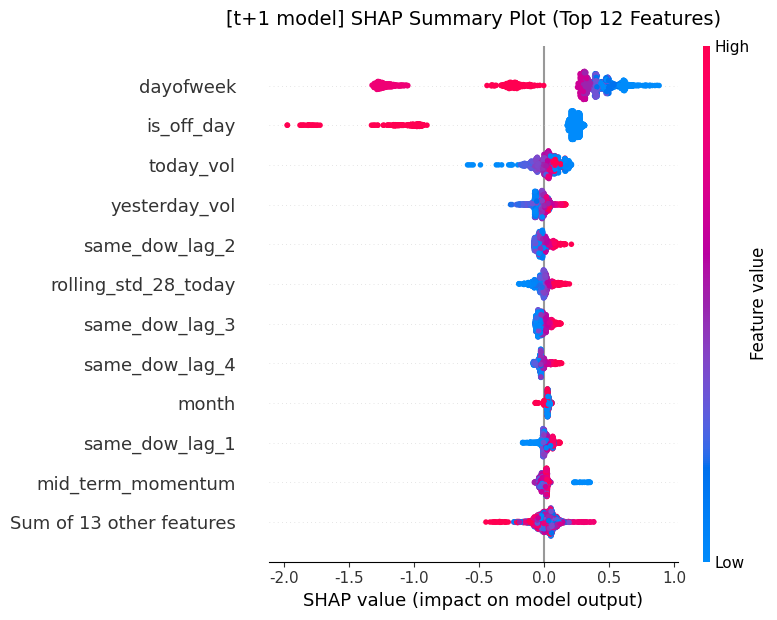

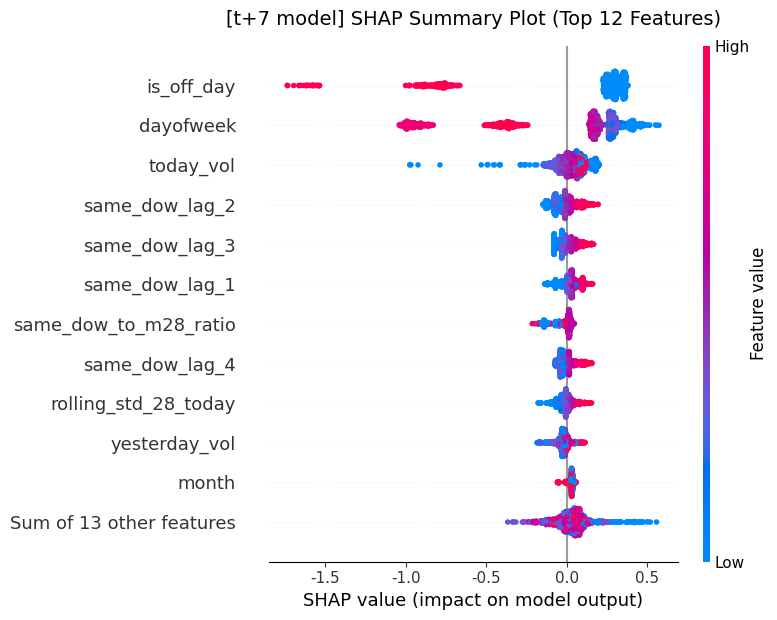

<Figure size 800x600 with 0 Axes>

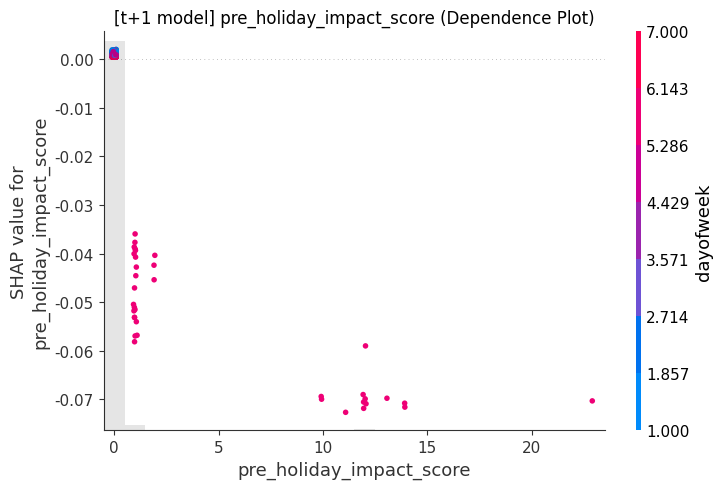

In [62]:
plt.rcdefaults()

shap_results = calculate_multistep_shap(trained_models, X_test_dict)

# 3. t+1 및 t+7 요약 비스웜 플롯 생성
plot_shap_summary(shap_results, step_name='t+1', top_n=12)
plot_shap_summary(shap_results, step_name='t+7', top_n=12)

# 4. 연휴 피처(pre_holiday_impact_score)의 비선형 효과 확인
plot_shap_dependence(shap_results, feature_name='pre_holiday_impact_score', step_name='t+1')
